# Weekly initial jobless claims

Estimate weekly noise from FRED’s ICSA series and calculate P(claims ≥ 200,000). Run cells from top to bottom using the **Python (prediction)** kernel.

The public FRED CSV endpoint requires no API key. Set `MY_MU` in the final cell to change your forecast center.

Two sampling methods are compared: (A) the last 52 weekly changes, and (B) the same week of November in past years (COVID years skipped). Each one gets a histogram check of the normality assumption before its probability is computed from the normal pdf.

## Imports and settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
from scipy.stats import norm

FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=ICSA"
N_WEEKS = 52          # reference window
STRIKE = 200_000      # Kalshi "at least 200,000"
SKIP_YEARS = {2020, 2021}   # COVID years excluded from the seasonal sample
START_YEAR = 1967          # first year of the seasonal sample (FRED starts in 1967)


## 1. Pull the data

In [2]:
df = pd.read_csv(FRED_URL)
df.columns = ["date", "claims"]           # FRED names them observation_date / ICSA
df["date"] = pd.to_datetime(df["date"])
df["claims"] = pd.to_numeric(df["claims"], errors="coerce")
df = df.dropna().set_index("date").sort_index()

## 2. Keep the last 52 weeks + 1 extra (need N+1 levels for N changes)

In [3]:
window = df["claims"].iloc[-(N_WEEKS + 1):]

## 3. Week-over-week changes

In [4]:
changes = window.diff().dropna()                     # in claims, e.g. -6000
log_changes = np.log(window).diff().dropna()        # ~ percent change

sigma = changes.std(ddof=1)                          # sample SD
sigma_log = log_changes.std(ddof=1)
last_level = window.iloc[-1]
last_date = window.index[-1].date()

# Robust check: if a few outlier weeks inflate the SD, these two will disagree
mad_sigma = 1.4826 * (changes - changes.median()).abs().median()

print(f"Window: {changes.index[0].date()} to {last_date}  ({len(changes)} changes)")
print(f"Last reported level (FRED, revised): {last_level:,.0f}  week ending {last_date}")
print()
print(f"Mean weekly change:        {changes.mean():>10,.0f}")
print(f"SD of weekly change:       {sigma:>10,.0f}   <- sigma")
print(f"Robust SD (MAD-based):     {mad_sigma:>10,.0f}")
print(f"SD of log change:          {sigma_log:>10.4f}  (~{sigma_log*last_level:,.0f} at current level)")
print(f"Largest up / down week:    {changes.max():>+10,.0f} / {changes.min():+,.0f}")

Window: 2025-11-15 to 2026-11-07  (52 changes)
Last reported level (FRED, revised): 200,000  week ending 2026-11-07

Mean weekly change:              -538
SD of weekly change:            9,327   <- sigma
Robust SD (MAD-based):          8,154
SD of log change:              0.0443  (~8,870 at current level)
Largest up / down week:       +19,000 / -25,000


## 3b. Is the spread normal? (52-week sample)

Histogram of the weekly changes with the fitted normal pdf on top, a Q-Q plot, and numeric checks. Heavy tails would show up as the Q-Q points peeling away from the line at the ends and as excess kurtosis > 0.

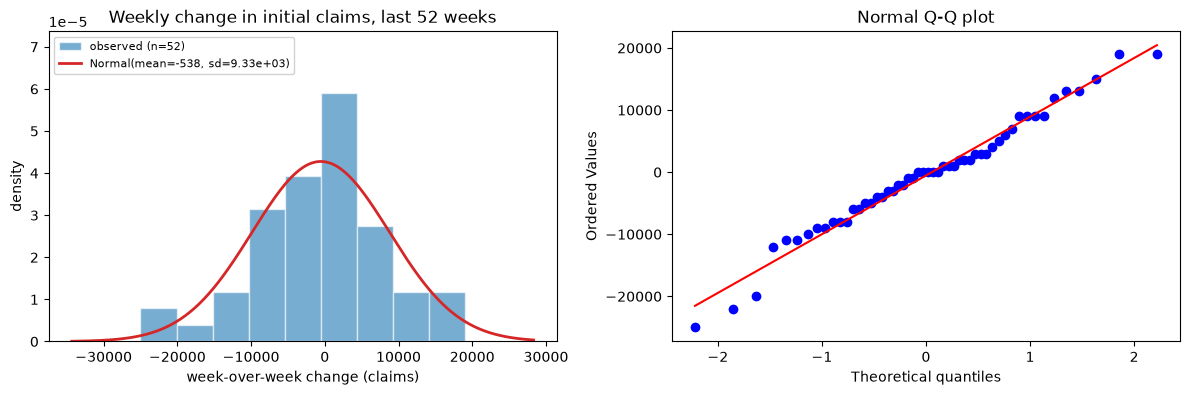

Skewness:         -0.23   (normal = 0)
Excess kurtosis:  +0.35   (normal = 0; > 0 means fat tails)
Shapiro-Wilk p:   0.476   (no evidence against normality at 5%)
Within 1 / 2 / 3 sd: 67% / 90% / 100%   (normal = 68% / 95% / 99.7%)
Note: with n this small the tests have low power; trust the plots as much as the p-value.


In [5]:
def normality_check(x, title, xlabel):
    """Histogram + fitted normal pdf, Q-Q plot, and numeric normality checks."""
    x = np.asarray(x, dtype=float)
    mu_hat, sd_hat = x.mean(), x.std(ddof=1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    ax1.hist(x, bins="auto", density=True, alpha=0.6, edgecolor="white", label=f"observed (n={len(x)})")
    grid = np.linspace(x.min() - sd_hat, x.max() + sd_hat, 400)
    ax1.plot(grid, norm.pdf(grid, mu_hat, sd_hat), lw=2, color="C3",
             label=f"Normal(mean={mu_hat:,.3g}, sd={sd_hat:,.3g})")
    ax1.margins(y=0.25)
    ax1.set(title=title, xlabel=xlabel, ylabel="density")
    ax1.legend(loc="upper left", fontsize=8, framealpha=0.9)

    stats.probplot(x, dist="norm", plot=ax2)
    ax2.set_title("Normal Q-Q plot")
    plt.tight_layout()
    plt.show()

    skew, ex_kurt = stats.skew(x), stats.kurtosis(x)      # both 0 for a normal
    sh_p = stats.shapiro(x).pvalue
    z = np.abs(x - mu_hat) / sd_hat
    print(f"Skewness:         {skew:+.2f}   (normal = 0)")
    print(f"Excess kurtosis:  {ex_kurt:+.2f}   (normal = 0; > 0 means fat tails)")
    print(f"Shapiro-Wilk p:   {sh_p:.3f}   ({'no evidence against normality' if sh_p > 0.05 else 'normality rejected'} at 5%)")
    print(f"Within 1 / 2 / 3 sd: {np.mean(z <= 1):.0%} / {np.mean(z <= 2):.0%} / {np.mean(z <= 3):.0%}"
          f"   (normal = 68% / 95% / 99.7%)")
    print("Note: with n this small the tests have low power; trust the plots as much as the p-value.")


normality_check(changes, "Weekly change in initial claims, last 52 weeks", "week-over-week change (claims)")

## 4. Probability across forecast centers

Use a 199,500 continuity correction for reporting in whole thousands.

In [6]:
threshold = STRIKE - 500
print(f"\nP(claims >= {STRIKE:,}) using sigma = {sigma:,.0f}")
for mu in range(192_000, 206_000, 1_000):
    p = 1 - norm.cdf((threshold - mu) / sigma)
    print(f"  mu = {mu:,}:  {p:6.1%}")


P(claims >= 200,000) using sigma = 9,327
  mu = 192,000:   21.1%
  mu = 193,000:   24.3%
  mu = 194,000:   27.8%
  mu = 195,000:   31.5%
  mu = 196,000:   35.4%
  mu = 197,000:   39.4%
  mu = 198,000:   43.6%
  mu = 199,000:   47.9%
  mu = 200,000:   52.1%
  mu = 201,000:   56.4%
  mu = 202,000:   60.6%
  mu = 203,000:   64.6%
  mu = 204,000:   68.5%
  mu = 205,000:   72.2%


## 5. Your forecast: set mu here once you've decided your center

The probability is the area under the normal pdf above the threshold, integrated numerically and cross-checked against the closed-form cdf.

In [7]:
def prob_at_least(mu, sd, strike=STRIKE):
    """P(X >= strike) for X ~ Normal(mu, sd): integrate the pdf over [strike - 500, inf)."""
    t = strike - 500                                  # continuity correction for whole-number claims
    area = quad(lambda x: norm.pdf(x, mu, sd), t, mu + 12 * sd)[0]
    return area, 1 - norm.cdf((t - mu) / sd)         # (pdf integral, cdf check)


MY_MU = 197_700   # Kalshi-implied forecast (~198K); last_level would be 200,000
p_pdf, p_cdf = prob_at_least(MY_MU, sigma)
print(f"\nYour mu = {MY_MU:,.0f}, sigma = {sigma:,.0f} (52-week sample)")
print(f"P(>= {STRIKE:,}) from pdf integral = {p_pdf:.1%}   (cdf check: {p_cdf:.1%})")


Your mu = 197,700, sigma = 9,327 (52-week sample)
P(>= 200,000) from pdf integral = 42.3%   (cdf check: 42.3%)


## 6. Second sampling method: this week of November across years

Instead of the last 52 weeks, take the change into the **same calendar week** (week ending Nov 11-17, i.e. the Nov 14 week we are forecasting) in every past year, skipping the COVID years. Levels differ hugely between decades (500k in the 1970s vs 200k now), so changes are measured in **log terms** (about % change) and rescaled to today's level.

In [8]:
in_week = (df.index.month == 11) & (df.index.day >= 11) & (df.index.day <= 17)
all_log = np.log(df["claims"]).diff()
seasonal = all_log[in_week].dropna()
seasonal = seasonal[(seasonal.index.year >= START_YEAR) & ~seasonal.index.year.isin(SKIP_YEARS)]

sigma_seas_log = seasonal.std(ddof=1)
mean_seas_log = seasonal.mean()
sigma_seas = sigma_seas_log * last_level            # rescale to today's level, in claims

print(f"Years used: {seasonal.index.year.min()}-{seasonal.index.year.max()}, skipping {sorted(SKIP_YEARS)}  (n={len(seasonal)})")
print(f"Mean log change this week:  {mean_seas_log:+.4f}  (~{mean_seas_log*last_level:+,.0f} claims at current level)")
print(f"SD of log change:           {sigma_seas_log:.4f}  (~{sigma_seas:,.0f} claims at current level)  <- sigma (seasonal)")
print(f"Compare 52-week sigma:      {sigma:,.0f}")
print()
print("Sensitivity to the start year (SD of log change -> claims):")
for sy in (1967, 1990, 2000, 2010):
    s = all_log[in_week].dropna()
    s = s[(s.index.year >= sy) & ~s.index.year.isin(SKIP_YEARS)]
    print(f"  from {sy}: n={len(s):>2}  sd={s.std(ddof=1):.4f}  ->  {s.std(ddof=1)*last_level:>6,.0f}")

Years used: 1967-2025, skipping [2020, 2021]  (n=57)
Mean log change this week:  -0.0084  (~-1,689 claims at current level)
SD of log change:           0.0399  (~7,977 claims at current level)  <- sigma (seasonal)
Compare 52-week sigma:      9,327

Sensitivity to the start year (SD of log change -> claims):
  from 1967: n=57  sd=0.0399  ->   7,977
  from 1990: n=34  sd=0.0351  ->   7,022
  from 2000: n=24  sd=0.0355  ->   7,095
  from 2010: n=14  sd=0.0406  ->   8,114


### 6b. Is the seasonal spread normal?

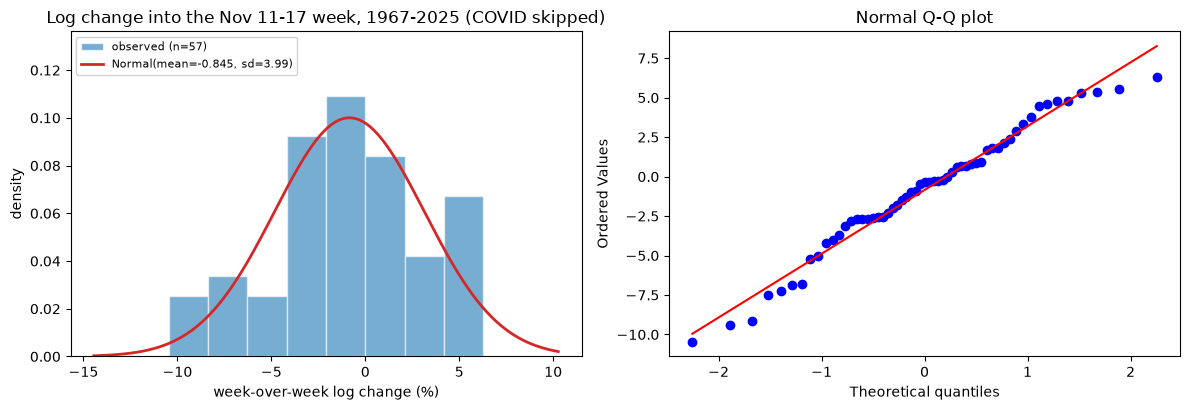

Skewness:         -0.35   (normal = 0)
Excess kurtosis:  -0.27   (normal = 0; > 0 means fat tails)
Shapiro-Wilk p:   0.252   (no evidence against normality at 5%)
Within 1 / 2 / 3 sd: 67% / 95% / 100%   (normal = 68% / 95% / 99.7%)
Note: with n this small the tests have low power; trust the plots as much as the p-value.


In [9]:
normality_check(seasonal * 100, f"Log change into the Nov 11-17 week, {seasonal.index.year.min()}-{seasonal.index.year.max()} (COVID skipped)",
                "week-over-week log change (%)")

### 6c. Probability from the seasonal normal pdf

In [10]:
print(f"P(claims >= {STRIKE:,}), seasonal sigma = {sigma_seas:,.0f}\n")
print(f"{'center':<34}{'mu':>10}{'pdf integral':>15}{'cdf check':>11}")
for label, mu in [("last level (no drift)", last_level),
                  ("last level + seasonal mean change", last_level * np.exp(mean_seas_log))]:
    a, b = prob_at_least(mu, sigma_seas)
    print(f"{label:<34}{mu:>10,.0f}{a:>15.1%}{b:>11.1%}")

print("\nAcross forecast centers:")
for mu in range(192_000, 206_000, 2_000):
    a, _ = prob_at_least(mu, sigma_seas)
    print(f"  mu = {mu:,}:  {a:6.1%}")

P(claims >= 200,000), seasonal sigma = 7,977

center                                    mu   pdf integral  cdf check
last level (no drift)                200,000          52.5%      52.5%
last level + seasonal mean change    198,318          44.1%      44.1%

Across forecast centers:
  mu = 192,000:   17.4%
  mu = 194,000:   24.5%
  mu = 196,000:   33.0%
  mu = 198,000:   42.5%
  mu = 200,000:   52.5%
  mu = 202,000:   62.3%
  mu = 204,000:   71.4%


## 7. Side-by-side

In [11]:
rows = []
for name, sd in [("Last 52 weeks", sigma), ("Same week, past years", sigma_seas)]:
    a, _ = prob_at_least(last_level, sd)
    rows.append({"method": name, "sigma": f"{sd:,.0f}", f"P(>= {STRIKE:,}) at mu = last level": f"{a:.1%}"})
pd.DataFrame(rows).set_index("method")

,sigma,"P(>= 200,000) at mu = last level"
method,,
Last 52 weeks,"9,327",52.1%
"Same week, past years","7,977",52.5%
